# AISE 3350A FW26 — Course Project Report
## Seeing Under Uncertainty: A Whole-Game, Confidence-Aware Player for Rock-Paper-Scissors-Minus-One

**Western University · Department of Electrical and Computer Engineering**
**Instructor:** Prof. Elvis Chen · **Due:** December 3, 2026, 11:59 p.m. (grace period to December 6)

| Team member | Student number |
|---|---|
| _Name 1_ | _000000000_ |
| _Name 2_ | _000000000_ |
| _Name 3_ | _000000000_ |
| _Name 4_ | _000000000_ |
| _Name 5 (if any)_ | _000000000_ |

---
# 🚧 STILL TO FINISH — read this first (delete this section before submitting)

### Where we are

The system is a chain: **📷 Camera → 👁️ Vision → 🧠 Strategy → 🖥️ Display**

| Part | What it does | Status |
|---|---|---|
| 1. Photos | We take photos of the four hands and upload them (no live camera needed) | ❌ Not started |
| 2. Vision | Finds the 4 hands (pre-trained neural network), decides whose they are and the **probability** of Rock/Paper/Scissors for each (two classifiers we train) | 🟡 Code written and tested on simulated hands (Section 2.7); needs the model file, real photos and labels |
| 3. Strategy | Recommends a pair to show (Stage 1) and which hand to keep (Stage 2); optional adaptive mode | ✅ Done and tested |
| 4. Display | Shows probabilities, confidence warnings and the hand to keep | ✅ Done, currently fed by typed-in hands |

Right now hands are typed in, e.g. `play_round(my_hands=["P","S"], opp_hands=["P","R"])`. The goal is for a photo to go in instead.

---

### For the camera & vision person — your steps, in order

The vision code is **already written** (Section 2.7). It uses machine learning in two layers:
1. A **pre-trained neural network** (Google's MediaPipe Hand Landmarker) finds each hand and 21 points on it.
2. Two **small classifiers we train on our own photos**: one decides whose hand it is (ours vs the opponent's), one decides the shape. Both give probabilities, which the strategy uses.

Your job is to feed it real photos and labels, then measure how well it does. Steps in order:

**Step A — Decide the camera setup (before taking any photos).**
- Our hands come from the bottom of the photo, fingers up; the opponent's from the top, fingers down. Fix the camera in one place (e.g. above the table looking down) and keep it there.
- Write it in **Section 2.6** with one photo of the setup.
- Work out whether the hand on the **left of the photo** is our player's **own left** hand. Set `IMAGE_LEFT_IS_PLAYERS_LEFT` in Section 2.7 to match.

**Step B — Get the hand model.** Download `hand_landmarker.task` into the `models/` folder (link in `models/README.md`) and `pip install -r requirements.txt`.

**Step C — Take the photos.**
- `images/train/` (for training and tuning; aim for 30–50 photos), `images/test/` (**only** for measuring, never for training; aim for 50+), `images/demo/` (the 5 we submit).
- Vary conditions on purpose: bright/dim, plain/busy background, tilted hands, different people and skin tones, sleeves/jewellery. Record each photo's conditions in `images/photos.csv`.

**Step D — Label the hands.**
- For each train and test photo, run `show_detections("images/train/photo1.jpg")`. It draws a number on every hand it found.
- Add one row per hand to `images/hand_labels.csv`: `filename, split, hand_index, owner, shape`, e.g. `photo1.jpg, train, 0, us, P`. (Example rows are in the file; delete them.)
- If the detector misses a hand, still note it in `photos.csv`: missed hands count as detection errors.

**Step E — Re-run the notebook.** The classifiers train automatically on the train photos (Section 2.7.1), and the full evaluation runs automatically on the test photos (Section 3.7): detection, player assignment (ML vs the simple rule), shape accuracy, confusion matrix, calibration, all with 95% confidence intervals.
- Tune settings (e.g. `min_hand_detection_confidence`, the number of neighbours) using **train photos only**.

**Step F — Explain the results** in Section 3.7: which conditions fail and why (dim light? overlapping hands? tilted scissors?). Explained failures still earn marks. Compare the ML owner classifier against the simple upright rule: this is the instructions' "test whether the rule reliably identifies the players".

**Step G — Demo images.** 5 photos in `images/demo/` and their correct labels in the Section 3.8 table.

---

### Everyone else
- [ ] Introduction (Section 1) · [ ] Discussion incl. societal impact (Section 4) · [ ] Conclusion (Section 5) · [ ] Contributions (Section 6) · [ ] Bibliography (Section 7)
- [ ] Interpret each result where a _TODO_ asks (the numbers are already computed)
- [ ] Optional demo video
- [ ] Final check: **Kernel → Restart & Run All** with no errors; submit notebook + `images/demo/` + any model files
---

# ⭐ What makes our approach different

Most groups will solve the Stage-2 $2\times2$ game with the lecture formula and train a classifier on the Kaggle dataset. We kept the required parts but made six design decisions to go further. Each is explained in its section.

| # | Typical approach | Our approach | Why |
|---|---|---|---|
| 1 | Solve only Stage 2 (which hand to keep) | **Solve the whole game**, including Stage 1 (which pair to show), by working backwards (Section 2.3) | The instructions only analyse Stage 2. Solving Stage 1 shows that showing two identical hands is a mistake and that Stage 1 is plain Rock-Paper-Scissors in disguise. |
| 2 | One closed-form $2\times2$ formula | **Two independent solvers** (geometric "tent" method and linear programming) that check each other (Section 2.2) | The formula fails when one hand dominates. LP is the standard general tool and also solves the $6\times6$ Stage-1 game. Agreement between two methods catches bugs. |
| 3 | Vision outputs one label per hand | Vision outputs **probabilities**, and the strategy plans with the **expected** payoff (Section 2.4) | The camera will sometimes be unsure. Treating a 55%-sure guess as certain throws information away. |
| 4 | Report vision accuracy only | **Translate vision errors into points lost per round** (Section 3.5) | The rubric asks us to quantify experimental error *and its impact*. This shows what each percent of accuracy is worth. |
| 5 | Always play the equilibrium | Optional **ε-safe adaptive mode** that learns an opponent's habits but caps the possible loss (Sections 2.5, 3.6) | Equilibrium is unbeatable but never punishes predictable opponents. Our mode does, with a guaranteed limit on the downside. |
| 6 | Train a CNN on the Kaggle dataset; decide owner by a hand-written rule | **Pre-trained hand-landmark network** plus **two small classifiers we train** on our own photos: one decides whose hand it is (with an "exactly two each" rule), one the shape. The hand-written rule is kept as a baseline to beat (Section 2.7) | The Kaggle images are single hands on a green background, unlike our photos. Working from 21 hand points instead of pixels ignores background and lighting, so a few dozen labelled photos are enough. The owner classifier learns from data and gives a probability, where a fixed rule breaks on tilted hands. |

# 0. Setup and Dependencies

**Requirements:** Python 3.10+, `numpy`, `matplotlib`, `scipy`, `scikit-learn`, `mediapipe`.
**Model file:** `models/hand_landmarker.task` (download link in `models/README.md`). Without it, everything except the photo-reading step still runs.

```bash
pip install -r requirements.txt
```
All paths are relative to this notebook. Run with **Kernel → Restart & Run All** (about a minute; the simulations take most of it).

In [1]:
# Imports, package versions and the random seed used for every reproducible test.
import sys
import platform
from pathlib import Path

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import linprog

SEED = 3350                  # fixed seed for every simulation
IMAGE_DIR = Path("images")   # relative path, works on any computer

print(f"Python {sys.version.split()[0]} on {platform.system()}")
print(f"numpy {np.__version__} | scipy {scipy.__version__} | matplotlib {matplotlib.__version__}")
print(f"Random seed: {SEED}")

Python 3.13.18 on Linux
numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2
Random seed: 3350


# 1. Introduction

> _TODO: turn into 2–3 paragraphs, written for a reader outside engineering._

- **What RPS-1 is:** each player shows two hands, then withdraws one ("minus one"); the remaining hands follow normal rock-paper-scissors rules. Popularized by _Squid Game_ Season 2 (2024), which makes a good opening hook.
- **Why it's interesting:** unlike normal RPS, players see all four hands before the decision that matters, so there is real strategy, and game theory gives a provably best answer.
- **Why it's a cyber-physical system:** a camera senses the physical world, software interprets and decides, a human acts. The key engineering question is how the decision should change when the sensing is imperfect, and this became the theme of our project.
- **Our contributions:** the six points in the table above, in one sentence each.
- **Roadmap** of the report.

# 2. Methods

## 2.1 System overview

| Step | Input | Output | Section |
|---|---|---|---|
| Stage-1 advice | — | Which pair to show (random, from the Stage-1 equilibrium) | 2.3 |
| Capture | Camera | Photo of 4 hands | 2.6 |
| Vision | Photo | For each hand: owner + probabilities of R/P/S | 2.7 |
| Strategy | Probabilities | Probability of keeping each of our hands | 2.2, 2.4, 2.5 |
| Display | Probabilities | Randomly selected hand to keep, confidence warnings | 2.8 |

## 2.2 The Stage-2 game and two ways to solve it

**Setting.** After Stage 1 all four hands are visible. Each player only decides which of their two hands to keep. A round scores +1 (win), 0 (tie), −1 (loss), and the game is **zero-sum**: our gain is the opponent's loss.

**Payoff matrix.** $A_{ij}$ is our payoff if we keep our hand $i$ and the opponent keeps their hand $j$. The instructions' example (us: Paper + Scissors, them: Paper + Rock):

| We keep \ They keep | Paper | Rock |
|---|---|---|
| **Paper** | 0 | +1 |
| **Scissors** | +1 | −1 |

**Maximin.** We keep hand 1 with probability $p$. Against each opponent choice $j$, our expected payoff is a straight line, $f_j(p) = pA_{1j} + (1-p)A_{2j}$. A good opponent picks the worse line for us, so we can **guarantee** $\min_j f_j(p)$, and we choose $p$ to make this as large as possible. The best guarantee is the **value of the game**, $v$. By von Neumann's minimax theorem, the opponent can hold us to exactly $v$, so both playing this way is a Nash equilibrium.

**Solver 1: the "tent" method (geometric).** The minimum of two lines forms a tent shape, and its peak is at $p=0$, at $p=1$, or where the lines cross:
$$p_{\text{cross}} = \frac{A_{22} - A_{21}}{(A_{11} - A_{21}) - (A_{12} - A_{22})}.$$
We check all three candidates and keep the best. **Why not just use the crossing formula?** When one hand is always at least as good (dominance, e.g. both players show Rock + Paper, where Paper never does worse), the crossing lies outside $[0,1]$ or doesn't exist, and the formula gives a wrong or undefined answer. Checking the endpoints fixes this.

**Solver 2: linear programming (general).** For any matrix game we solve
$$\max_{x,\,v}\; v \quad \text{subject to}\quad \sum_i x_i A_{ij} \ge v \;\;\forall j,\qquad \sum_i x_i = 1,\qquad x_i \ge 0,$$
with SciPy's `linprog`. **Why add it?** It works for any size of game, which we need for Stage 1 ($6\times6$, Section 2.3), and it is a completely independent method. In Section 3.2 we check both solvers agree on all 81 possible Stage-2 situations, which gives strong evidence neither has a bug. We use the fast tent method inside large simulations and LP elsewhere.

**Randomizing.** Each round we draw the hand to keep at random with probability $p^*$. Always picking the more likely hand would make us predictable, which is exactly what a mixed strategy prevents.

In [2]:
# ============================================================================
# Core game model and solvers
# ============================================================================
SHAPES = ["R", "P", "S"]
NAMES = {"R": "Rock", "P": "Paper", "S": "Scissors"}

# RPS_PAYOFF[a, b] = our payoff for throwing SHAPES[a] against SHAPES[b]
RPS_PAYOFF = np.array([[ 0, -1,  1],    # Rock     vs R, P, S
                       [ 1,  0, -1],    # Paper    vs R, P, S
                       [-1,  1,  0]],   # Scissors vs R, P, S
                      dtype=float)


def to_probs(hand):
    """A hand can be a letter like "P" (certain) or probabilities [pR, pP, pS]."""
    if isinstance(hand, str):
        probs = np.zeros(3)
        probs[SHAPES.index(hand)] = 1.0
        return probs
    probs = np.asarray(hand, dtype=float)
    return probs / probs.sum()            # make sure they add up to 1


def payoff_matrix(my_hands, opp_hands):
    """A[i, j] = our EXPECTED payoff if we keep my_hands[i] and they keep opp_hands[j].
    With letters this is just +1 / 0 / -1. With probabilities it averages over
    every possible true shape of both hands (Section 2.4)."""
    A = np.zeros((len(my_hands), len(opp_hands)))
    for i, mine in enumerate(my_hands):
        for j, theirs in enumerate(opp_hands):
            A[i, j] = to_probs(mine) @ RPS_PAYOFF @ to_probs(theirs)
    return A


def guaranteed_payoff(A, p):
    """Worst-case expected payoff (over the opponent's 2 choices) if we keep
    hand 1 with probability p. Works for a single p or an array of p values."""
    line_1 = p * A[0, 0] + (1 - p) * A[1, 0]   # opponent keeps their hand 1
    line_2 = p * A[0, 1] + (1 - p) * A[1, 1]   # opponent keeps their hand 2
    return np.minimum(line_1, line_2)


def solve_2x2(A):
    """Solver 1 - 'tent' method for a 2x2 zero-sum game.
    Returns (probabilities of keeping each of our hands, game value)."""
    candidates = [0.0, 1.0]
    denom = (A[0, 0] - A[1, 0]) - (A[0, 1] - A[1, 1])
    if denom != 0:
        p_cross = (A[1, 1] - A[1, 0]) / denom
        if 0 < p_cross < 1:
            candidates.append(p_cross)

    values = [guaranteed_payoff(A, p) for p in candidates]
    best = max(values)

    # If our choice makes no difference (identical hands), report 50/50.
    if np.isclose(guaranteed_payoff(A, 0.0), guaranteed_payoff(A, 1.0)) and \
       np.isclose(guaranteed_payoff(A, 0.5), best):
        return np.array([0.5, 0.5]), float(best)

    optimal = [p for p, v in zip(candidates, values) if np.isclose(v, best)]
    p = optimal[-1]                         # prefer the mixed (crossing) solution if tied
    return np.array([p, 1 - p]), float(best)


def solve_lp(A):
    """Solver 2 - linear programming for ANY m x n zero-sum game.
    Variables are [x_1 .. x_m, v]; we maximize v (linprog minimizes, so use -v)."""
    m, n = A.shape
    cost = np.zeros(m + 1)
    cost[-1] = -1
    # For every opponent column j:  v - sum_i x_i A[i, j] <= 0
    A_ub = np.hstack([-A.T, np.ones((n, 1))])
    b_ub = np.zeros(n)
    # Probabilities add up to 1
    A_eq = np.zeros((1, m + 1))
    A_eq[0, :m] = 1
    bounds = [(0, None)] * m + [(None, None)]
    res = linprog(cost, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=[1], bounds=bounds)
    x = np.clip(res.x[:m], 0, None)
    return x / x.sum(), float(res.x[-1])


def solve_game(A):
    """Use the fast tent method for 2x2 games and LP for anything larger."""
    return solve_2x2(A) if A.shape == (2, 2) else solve_lp(A)


print("Game model and both solvers loaded.")

Game model and both solvers loaded.


## 2.3 Solving the whole game: what pair should we show?

The instructions analyse only Stage 2. But a player also chooses which two shapes to show in Stage 1, and that choice determines which Stage-2 game they end up in. We solve it with **backward induction**, the standard method for multi-stage games (it finds a _subgame-perfect equilibrium_, Selten 1965):

1. For every possible pair we could show and every pair the opponent could show, solve the Stage-2 game and record its value $v$.
2. Put those values in a new matrix: rows = our pair, columns = their pair. This is the **Stage-1 game**.
3. Solve the Stage-1 game with LP.

Order within a pair doesn't change the strategy, so there are 6 pairs: RR, PP, SS, RP, RS, PS. **We include identical pairs** (the instructions ask whether we support them). Our system handles them in both stages.

**What we found** (computed in Section 3.3):
- **Never show two identical hands.** Against a good opponent, RR, PP or SS costs 2/3 of a point per round on average, while any mixed pair breaks even.
- **Stage 1 is Rock-Paper-Scissors in disguise.** Among the mixed pairs, RP beats RS, RS beats PS, and PS beats RP, each by exactly 1/3 point. The reason: each pair behaves like its **stronger shape**. RP acts like Paper (Paper beats Rock), RS like Rock, PS like Scissors, and those three follow the usual RPS cycle. So the best Stage-1 strategy is to pick RP, RS or PS **uniformly at random**, and the overall game is fair (value 0).

In [3]:
STAGE1_PAIRS = ["RR", "PP", "SS", "RP", "RS", "PS"]


def stage1_matrix():
    """V[i, j] = value of the Stage-2 game if we show STAGE1_PAIRS[i]
    and the opponent shows STAGE1_PAIRS[j] (backward induction step 1-2)."""
    n = len(STAGE1_PAIRS)
    V = np.zeros((n, n))
    for i, ours in enumerate(STAGE1_PAIRS):
        for j, theirs in enumerate(STAGE1_PAIRS):
            V[i, j] = solve_game(payoff_matrix(list(ours), list(theirs)))[1]
    return V


STAGE1_V = stage1_matrix()
STAGE1_PROBS, STAGE1_VALUE = solve_lp(STAGE1_V)     # backward induction step 3


def recommend_stage1(rng):
    """Randomly choose which pair to show, using the Stage-1 equilibrium."""
    return STAGE1_PAIRS[rng.choice(len(STAGE1_PAIRS), p=STAGE1_PROBS)]


print("Stage-1 equilibrium (probability of showing each pair):")
for pair, prob in zip(STAGE1_PAIRS, STAGE1_PROBS):
    print(f"  {pair}: {prob:.3f}")
print(f"Value of the whole game: {np.round(STAGE1_VALUE, 6) + 0.0:+.3f}")

Stage-1 equilibrium (probability of showing each pair):
  RR: 0.000
  PP: 0.000
  SS: 0.000
  RP: 0.333
  RS: 0.333
  PS: 0.333
Value of the whole game: +0.000


## 2.4 Deciding under uncertainty: using the camera's confidence

**The problem.** A vision model is never 100% sure. Most systems take its best guess and treat it as fact. If it is 55% sure a hand is Paper, the strategy still acts as if it's certainly Paper.

**Our approach.** The vision part gives each hand a probability for each shape, e.g. $[0.05, 0.85, 0.10]$ for Rock, Paper, Scissors. We then build the payoff matrix from **expected** payoffs, averaging over every possible true shape:
$$A_{ij} = \sum_{s}\sum_{t} \Pr(\text{our hand } i = s)\,\Pr(\text{their hand } j = t)\,\text{payoff}(s, t) = \mathbf{m}_i^\top P\,\mathbf{o}_j,$$
where $P$ is the $3\times3$ RPS payoff table. This is one line of code (`payoff_matrix` above), and when the vision is certain it gives exactly the normal matrix, so nothing else changes.

**Where it matters most.** Our own player can see and confirm their own hands, so in practice the uncertainty that really matters is about the **opponent's** hands. The method treats both the same way.

**Why this is reasonable.** When the camera is sure, nothing changes. When it's unsure about a hand, that hand's payoffs are "blurred" toward the average, and the strategy naturally leans on hands it trusts more.

**Assumption to check:** the probabilities must be **calibrated**, meaning "90% sure" should be right about 90% of the time (Guo et al., 2017). The vision team tests this in Section 3.7.

**Display safety net.** If any hand's top probability is below 70%, the display warns the player to double-check that hand before acting.

## 2.5 Optional adaptive mode: ε-safe exploitation

**Limitation of the equilibrium.** It guarantees our average whatever the opponent does, but it **never takes advantage** of a predictable opponent. Against someone who always keeps Rock, it still only earns the equilibrium value.

**Our model of the opponent.** Real people have favourite shapes. For each shape we track how often the opponent keeps it when they show it:
$$\text{keep rate}(s) = \frac{\text{times kept } s + 1}{\text{times shown } s + 2}.$$
The $+1$ and $+2$ (Laplace smoothing) start every rate at 1/2, so one early round can't make the model overconfident. With opponent hands $(b_1, b_2)$ we predict $\Pr(\text{they keep } b_1) = \frac{\text{rate}(b_1)}{\text{rate}(b_1) + \text{rate}(b_2)}$.

**ε-safe best response.** Fully trusting the model is risky: if it's wrong, a clever opponent punishes us. So we only consider strategies whose **guaranteed** payoff is at least $v - \varepsilon$, and among those, pick the one with the highest expected payoff against the model's prediction:
$$p^* = \arg\max_{p}\; \mathbb{E}_{\text{model}}[\text{payoff}(p)] \quad\text{subject to}\quad \min_j f_j(p) \ge v - \varepsilon.$$
We search 101 values of $p$ from 0 to 1, which is simple and fast enough. $\varepsilon$ is a **dial**: $\varepsilon = 0$ is pure equilibrium (no risk); larger $\varepsilon$ exploits more but can lose up to $\varepsilon$ per round if the model is wrong. This idea comes from research on "safe opponent exploitation" (Ganzfried & Sandholm, 2015). Section 3.6 measures the trade-off.

**Default:** off in competition, since we know nothing about our opponent at the start. It's an option for longer matches.

In [4]:
class OpponentModel:
    """Learns how often the opponent keeps each shape when they show it."""

    def __init__(self):
        self.kept = {s: 1 for s in SHAPES}    # Laplace smoothing: every rate starts at 1/2
        self.shown = {s: 2 for s in SHAPES}

    def keep_rate(self, shape):
        return self.kept[shape] / self.shown[shape]

    def predict(self, opp_hands):
        """Predicted probability that the opponent keeps opp_hands[0]."""
        r1, r2 = self.keep_rate(opp_hands[0]), self.keep_rate(opp_hands[1])
        return r1 / (r1 + r2)

    def update(self, opp_hands, kept_index):
        """Record what the opponent did this round."""
        for shape in opp_hands:
            self.shown[shape] += 1
        self.kept[opp_hands[kept_index]] += 1


def safe_exploit(A, q_predicted, epsilon):
    """Best keep-probabilities against the model's prediction q_predicted,
    never accepting a guaranteed payoff below (game value - epsilon)."""
    p_eq, value = solve_2x2(A)
    if epsilon <= 0:
        return p_eq
    p_grid = np.linspace(0, 1, 101)
    q = np.array([q_predicted, 1 - q_predicted])
    expected = p_grid * (A[0] @ q) + (1 - p_grid) * (A[1] @ q)     # vs the model
    allowed = guaranteed_payoff(A, p_grid) >= value - epsilon - 1e-9
    # Small tie-break toward the equilibrium so we never become predictable for no gain
    score = np.where(allowed, expected - 1e-6 * np.abs(p_grid - p_eq[0]), -np.inf)
    p = p_grid[np.argmax(score)]
    return np.array([p, 1 - p])


print("Adaptive mode loaded.")

Adaptive mode loaded.


## 2.6 Capture setup

> _TODO (camera/vision): describe and photograph the setup:_ camera and position (height, angle, distance), which side each player sits on, how image left/right maps to **our player's own** left/right (and the value of `IMAGE_LEFT_IS_PLAYERS_LEFT`), background and lighting, restrictions (no overlapping hands, sleeves up, plain table).

## 2.7 Vision: finding the hands, deciding whose they are, classifying them

The instructions ask us to identify whose hands are whose and classify each one, "ideally using machine learning". We use machine learning in two layers.

| Step | What happens | Method | Trained by |
|---|---|---|---|
| 1. Find hands | Up to 4 hands, each as 21 points (wrist, knuckles, fingertips) | MediaPipe Hand Landmarker, a pre-trained deep neural network | Google (transfer learning) |
| 2. Features | Points → a few numbers per hand: which way it points and where it sits (owner); how far each fingertip reaches after turning the hand upright (shape) | Geometry | — |
| 3. Whose hand? | Probability that each hand is ours; the two most likely are ours ("exactly two each" rule) | Logistic regression | **Us**, on labelled training photos |
| 4. Which shape? | Probability of Rock, Paper, Scissors for each hand | k-nearest neighbours **or** logistic regression, whichever wins 5-fold cross-validation | **Us**, on labelled training photos |
| 5. Left/right | Our two hands ordered by the player's own left and right | Position in the photo + the capture-setup rule | — |

**Why this design** (Engineering Tools):
- **Transfer learning for detection.** Training a hand detector from scratch would need thousands of labelled photos; reusing a network trained on a large hand dataset needs none.
- **Points instead of pixels.** Classifying 21 points instead of raw images ignores background, lighting and skin tone, so a few dozen labelled photos (4 hands each) are enough. It also lets us use the Kaggle images as extra shape data: run the landmarker on them, and their green background stops mattering.
- **Turning every hand upright before classifying shape.** After `normalize_hand`, the opponent's upside-down hands look the same as ours, so one shape classifier serves all four hands.
- **A learned owner classifier plus a game rule.** A fixed rule ("fingertips above the wrist = ours") breaks when hands tilt. The classifier learns from data and outputs a probability, and the rule that each player has exactly two hands corrects single mistakes. We keep the fixed rule as a **baseline** and compare both on test photos, which answers the instructions' request to test the upright/upside-down rule.
- **Probabilities out.** Both classifiers output probabilities, which feed the uncertainty-aware strategy (Section 2.4).
- **Fallback for upside-down hands.** Pre-trained hand models mostly see upright hands. If fewer than 4 hands are found, we also run the detector on the photo turned 180° and add any new hands.

**Limitations to report:** the detector is a black box we can't retrain; the classifiers are only as good as our small training set; the owner features assume the fixed camera setup of Section 2.6.

> _TODO (vision): add the model version and download URL, final settings, and what had to be changed to make it work._

In [5]:
# ============================================================================
# Vision, step 1: find the hands with a pre-trained neural network (MediaPipe)
# ============================================================================
try:
    import mediapipe as mp
    from mediapipe.tasks.python import vision as mp_vision
    from mediapipe.tasks.python.core.base_options import BaseOptions
    HAVE_MEDIAPIPE = True
except ImportError:
    HAVE_MEDIAPIPE = False

MODEL_PATH = Path("models") / "hand_landmarker.task"   # see models/README.md to download it

# MediaPipe numbers the 21 points on a hand like this:
WRIST = 0
THUMB_TIP, INDEX_MCP, INDEX_TIP = 4, 5, 8
MIDDLE_MCP, MIDDLE_TIP = 9, 12
FINGERTIPS = [4, 8, 12, 16, 20]          # thumb, index, middle, ring, pinky


def _run_landmarker(mp_image):
    options = mp_vision.HandLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=str(MODEL_PATH)),
        num_hands=4,                          # we expect four hands
        min_hand_detection_confidence=0.3)    # TODO (vision): tune on training photos
    with mp_vision.HandLandmarker.create_from_options(options) as detector:
        result = detector.detect(mp_image)
    # Each hand -> a (21, 2) array of (x, y), as fractions of image width/height (y points down)
    return [np.array([[p.x, p.y] for p in hand]) for hand in result.hand_landmarks]


def find_hands(image_path):
    """Return a list of hands, each a (21, 2) array of landmark points.

    Pre-trained hand models see mostly upright hands, so if fewer than 4 hands are
    found we also run the model on the photo turned 180 degrees and add any hand
    it finds that we don't already have (mapped back to the original photo)."""
    if not HAVE_MEDIAPIPE:
        raise ImportError("mediapipe is not installed: pip install mediapipe")
    if not MODEL_PATH.exists():
        raise FileNotFoundError(f"Hand model not found at {MODEL_PATH}: see models/README.md")

    image = mp.Image.create_from_file(str(image_path))
    hands = _run_landmarker(image)
    if len(hands) < 4:
        turned = np.ascontiguousarray(np.rot90(image.numpy_view(), 2))
        extra = _run_landmarker(mp.Image(image_format=image.image_format, data=turned))
        for hand in extra:
            hand = 1.0 - hand                                   # undo the 180-degree turn
            is_new = all(np.linalg.norm(hand[WRIST] - h[WRIST]) > 0.05 for h in hands)
            if is_new:
                hands.append(hand)
    return hands


# ============================================================================
# Vision, step 2: turn the 21 points into features for our two classifiers
# ============================================================================

def owner_features(points):
    """Which way the hand points, and where its wrist sits in the photo.
    [x and y of the unit vector wrist -> middle knuckle, wrist height]"""
    direction = points[MIDDLE_MCP] - points[WRIST]
    direction = direction / np.linalg.norm(direction)
    return np.array([direction[0], direction[1], points[WRIST, 1]])


def normalize_hand(points):
    """Move the wrist to (0, 0), rotate so the hand points straight up and
    scale so wrist -> middle knuckle has length 1. After this, an upside-down
    opponent hand looks the same as one of ours."""
    centred = points - points[WRIST]
    dx, dy = centred[MIDDLE_MCP]
    angle = np.arctan2(dx, -dy)              # how far the hand is turned from 'up'
    c, s = np.cos(angle), np.sin(angle)
    rotation = np.array([[c, s], [-s, c]])   # turns the hand back by that angle
    upright = centred @ rotation.T
    return upright / np.hypot(dx, dy)


def shape_features(points):
    """Seven numbers that describe the hand shape and don't change when the
    hand is rotated, resized or mirrored (left vs right hand)."""
    hand = normalize_hand(points)
    reach = np.linalg.norm(hand[FINGERTIPS], axis=1)                     # 5: how far each tip reaches
    v_gap = np.linalg.norm(hand[INDEX_TIP] - hand[MIDDLE_TIP])          # the 'V' of scissors
    thumb_out = np.linalg.norm(hand[THUMB_TIP] - hand[INDEX_MCP])       # thumb tucked or out
    return np.concatenate([reach, [v_gap, thumb_out]])


def upright_rule(points):
    """Baseline (no ML): a hand is ours if its middle fingertip is above its wrist."""
    return points[MIDDLE_TIP, 1] < points[WRIST, 1]      # y points down in images


print("Vision step 1 (detector) available:", HAVE_MEDIAPIPE and MODEL_PATH.exists())

Vision step 1 (detector) available: False


In [6]:
# ============================================================================
# Vision, steps 3-5: our two classifiers, player assignment, left/right
# ============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

# TODO (vision): set from the capture setup. True if the hand on the LEFT of the
# photo is the player's own LEFT hand (camera behind/above the player).
IMAGE_LEFT_IS_PLAYERS_LEFT = True


def train_owner_model(hands, owners):
    """Logistic regression: features -> probability the hand is ours (owner = 1)."""
    X = np.array([owner_features(h) for h in hands])
    model = make_pipeline(StandardScaler(), LogisticRegression())
    return model.fit(X, owners)


def train_shape_model(hands, shapes, verbose=True):
    """Compare two classifiers with 5-fold cross-validation on the TRAINING
    hands only, and keep the better one. Both output probabilities."""
    X = np.array([shape_features(h) for h in hands])
    candidates = {
        "k-nearest neighbours (k=7)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
        "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    }
    scores = {name: cross_val_score(m, X, shapes, cv=5).mean() for name, m in candidates.items()}
    best = max(scores, key=scores.get)
    if verbose:
        for name, score in scores.items():
            print(f"  shape model {name:<28} cross-validated accuracy {score:.3f}")
        print(f"  -> using {best}")
    return candidates[best].fit(X, shapes)


def assign_and_classify(hands, owner_model, shape_model):
    """Steps 3-5: decide whose hands are whose, classify shapes, order ours LEFT/RIGHT."""
    if len(hands) < 2:
        raise RuntimeError(f"Only {len(hands)} hand(s) found; need 4.")
    p_ours = owner_model.predict_proba(np.array([owner_features(h) for h in hands]))[:, 1]
    order = np.argsort(-p_ours)                     # most likely ours first
    ours = [hands[i] for i in order[:2]]            # game rule: exactly two hands each
    theirs = [hands[i] for i in order[2:4]]

    ours.sort(key=lambda h: h[WRIST, 0])            # left of photo first
    if not IMAGE_LEFT_IS_PLAYERS_LEFT:
        ours.reverse()

    # Probabilities in the order of SHAPES = [R, P, S]
    cols = [list(shape_model.classes_).index(s) for s in SHAPES]
    shape_probs = lambda group: [list(shape_model.predict_proba([shape_features(h)])[0][cols]) for h in group]
    return {"my_hands": shape_probs(ours), "opp_hands": shape_probs(theirs),
            "owner_confidence": p_ours[order[:4]], "n_found": len(hands)}


OWNER_MODEL, SHAPE_MODEL = None, None   # trained in Section 2.7.1 once labelled photos exist


def detect_hands(image_path):
    """The full vision pipeline used by play_round():
    photo -> find hands -> whose are whose -> shape probabilities."""
    if OWNER_MODEL is None or SHAPE_MODEL is None:
        raise RuntimeError("Vision classifiers not trained yet: add labelled photos (Section 2.7.1).")
    return assign_and_classify(find_hands(image_path), OWNER_MODEL, SHAPE_MODEL)

### 2.7.1 Training on our photos

Labelling workflow: `show_detections(path)` draws a number on each hand found; we record each hand's owner and shape in `images/hand_labels.csv`. The cell below trains both classifiers on the **train** photos only, choosing the shape model by cross-validation. Test photos are never used here.

In [7]:
# ============================================================================
# 2.7.1 Training the classifiers on our own labelled photos
# ============================================================================
import csv

HAND_LABELS = IMAGE_DIR / "hand_labels.csv"   # filename, split, hand_index, owner (us/them), shape (R/P/S)


def show_detections(image_path):
    """Labelling helper: draws each detected hand with its number, so a person
    can fill in hand_labels.csv (which number is whose, and which shape)."""
    hands = find_hands(image_path)
    img = plt.imread(image_path)
    h, w = img.shape[:2]
    plt.figure(figsize=(6, 5))
    plt.imshow(img)
    for i, pts in enumerate(hands):
        plt.plot(pts[:, 0] * w, pts[:, 1] * h, ".", ms=4)
        plt.text(pts[WRIST, 0] * w, pts[WRIST, 1] * h, str(i), color="yellow", fontsize=16,
                 fontweight="bold", bbox=dict(facecolor="black", alpha=0.6))
    plt.axis("off")
    plt.title(f"{Path(image_path).name}: {len(hands)} hands found")
    plt.show()


def load_labelled_hands(split):
    """Run the detector on every photo in a split and pair each hand with its label."""
    rows = [r for r in csv.DictReader(open(HAND_LABELS)) if r["split"] == split]
    by_photo = {}
    for r in rows:
        by_photo.setdefault(r["filename"], []).append(r)
    hands, owners, shapes, photo_of = [], [], [], []
    for filename, labels in by_photo.items():
        found = find_hands(IMAGE_DIR / split / filename)
        for r in labels:
            i = int(r["hand_index"])
            if i < len(found):
                hands.append(found[i])
                owners.append(1 if r["owner"] == "us" else 0)
                shapes.append(r["shape"])
                photo_of.append(filename)
    return hands, np.array(owners), np.array(shapes), photo_of


def labelled_photos_exist(split):
    return (HAND_LABELS.exists() and HAVE_MEDIAPIPE and MODEL_PATH.exists()
            and any(r["split"] == split for r in csv.DictReader(open(HAND_LABELS))))


if labelled_photos_exist("train"):
    train_hands, train_owners, train_shapes, _ = load_labelled_hands("train")
    print(f"Training on {len(train_hands)} labelled hands")
    OWNER_MODEL = train_owner_model(train_hands, train_owners)
    SHAPE_MODEL = train_shape_model(train_hands, train_shapes)
else:
    print("No labelled training photos yet (or no hand model): vision classifiers not trained.")
    print("The strategy still works with typed-in hands; see 'STILL TO FINISH'.")

No labelled training photos yet (or no hand model): vision classifiers not trained.
The strategy still works with typed-in hands; see 'STILL TO FINISH'.


### 2.7.2 Code check on simulated hands

Before real photos exist, we checked that steps 2–5 do what they should, using **simulated** hands: 21-point hands generated from a template with known owner and shape, with random tilt, size, position, mirroring and noise. These numbers test the **code**, not the real system: simulated hands are cleaner than real ones. Real accuracy is measured in Section 3.7.

In [8]:
# ============================================================================
# 2.7.2 Code check on SIMULATED hands (not a result - real accuracy is in 3.7)
# ============================================================================
# Before real photos exist, we test that steps 2-5 work as intended by
# generating fake 21-point hands with known owner and shape: random tilt,
# size, position, left/right mirroring and noise.

def fake_hand(shape, ours, rng, noise=0.04, tilt_deg=25):
    """A simulated MediaPipe hand: upright template -> bend fingers -> tilt, mirror, place."""
    mcp = {"thumb": (0.30, -0.25), "index": (-0.32, -0.95), "middle": (0.0, -1.0),
           "ring": (0.25, -0.93), "pinky": (0.45, -0.82)}
    extended = {"R": [], "P": ["thumb", "index", "middle", "ring", "pinky"],
                "S": ["index", "middle"]}[shape]
    spread = {"index": -0.25, "middle": 0.25} if shape == "S" else {}
    pts = [(0.0, 0.0)]
    for finger in ["thumb", "index", "middle", "ring", "pinky"]:
        x, y = mcp[finger]
        if finger in extended:
            tilt = spread.get(finger, 0.0) + (0.6 if finger == "thumb" else 0.0)
            steps = [0.45, 0.8, 1.05]                         # joints along the finger
            joints = [(x + d * np.sin(tilt), y - d * np.cos(tilt)) for d in steps]
        else:
            joints = [(x, y - 0.3), (x * 0.8, y - 0.15), (x * 0.6, y + 0.15)]   # curled
            if finger == "thumb":
                joints = [(0.25, -0.45), (0.1, -0.6), (-0.1, -0.65)]           # tucked thumb
        pts += [(x, y)] + joints
    pts = np.array(pts) + rng.normal(0, noise, (21, 2))      # landmark noise

    if rng.random() < 0.5:
        pts[:, 0] *= -1                                       # left vs right hand
    angle = rng.normal(0, np.radians(tilt_deg)) + (0 if ours else np.pi)
    c, s = np.cos(angle), np.sin(angle)
    pts = pts @ np.array([[c, -s], [s, c]]).T                 # tilt
    scale = rng.uniform(0.06, 0.12)                           # hand size in the photo
    centre = (rng.uniform(0.15, 0.85), rng.uniform(0.6, 0.9) if ours else rng.uniform(0.1, 0.4))
    return pts * scale + centre


def fake_photo(rng, noise=0.04, tilt_deg=25):
    """Four simulated hands: two ours, two theirs, random shapes."""
    shapes = rng.choice(SHAPES, size=4)
    owners = [1, 1, 0, 0]
    hands = [fake_hand(s, o == 1, rng, noise, tilt_deg) for s, o in zip(shapes, owners)]
    return hands, owners, list(shapes)


conditions = {"easy: small tilt, clean points": (0.04, 25),
              "hard: big tilt, noisy points": (0.15, 60)}
rng = np.random.default_rng(SEED)
for name, (noise, tilt) in conditions.items():
    train = [fake_photo(rng, noise, tilt) for _ in range(40)]   # 40 photos = 160 hands
    sim_hands = [h for photo in train for h in photo[0]]
    sim_owners = np.array([o for photo in train for o in photo[1]])
    sim_shapes = np.array([s for photo in train for s in photo[2]])
    print(f"=== {name} ===")
    sim_owner_model = train_owner_model(sim_hands, sim_owners)
    sim_shape_model = train_shape_model(sim_hands, sim_shapes)

    # normalize_hand must turn every hand upright
    assert np.allclose(normalize_hand(sim_hands[0])[MIDDLE_MCP], [0, -1])

    test = [fake_photo(rng, noise, tilt) for _ in range(100)]   # 100 NEW photos
    owner_ok, rule_ok, shape_ok, n = 0, 0, 0, 0
    for hands, owners, shapes in test:
        p_ours = sim_owner_model.predict_proba(np.array([owner_features(h) for h in hands]))[:, 1]
        picked = set(np.argsort(-p_ours)[:2])
        owner_ok += sum((i in picked) == (o == 1) for i, o in enumerate(owners))
        rule_ok += sum(upright_rule(h) == (o == 1) for h, o in zip(hands, owners))
        pred = sim_shape_model.predict(np.array([shape_features(h) for h in hands]))
        shape_ok += int(np.sum(pred == np.array(shapes)))
        n += 4
    print(f"  On 100 new simulated photos ({n} hands):")
    print(f"    owner, ML classifier + 'two each' rule: {owner_ok}/{n} = {owner_ok / n:.1%}")
    print(f"    owner, upright rule (baseline):         {rule_ok}/{n} = {rule_ok / n:.1%}")
    print(f"    shape classifier:                       {shape_ok}/{n} = {shape_ok / n:.1%}\n")

out = assign_and_classify(test[0][0], sim_owner_model, sim_shape_model)
print("What detect_hands() returns for one photo (probabilities of R, P, S):")
print("  my_hands :", np.round(out["my_hands"], 2).tolist())
print("  opp_hands:", np.round(out["opp_hands"], 2).tolist())

=== easy: small tilt, clean points ===
  shape model k-nearest neighbours (k=7)   cross-validated accuracy 1.000
  shape model logistic regression          cross-validated accuracy 1.000
  -> using k-nearest neighbours (k=7)


  On 100 new simulated photos (400 hands):
    owner, ML classifier + 'two each' rule: 400/400 = 100.0%
    owner, upright rule (baseline):         399/400 = 99.8%
    shape classifier:                       400/400 = 100.0%

=== hard: big tilt, noisy points ===
  shape model k-nearest neighbours (k=7)   cross-validated accuracy 0.988
  shape model logistic regression          cross-validated accuracy 0.994
  -> using logistic regression
  On 100 new simulated photos (400 hands):
    owner, ML classifier + 'two each' rule: 400/400 = 100.0%
    owner, upright rule (baseline):         349/400 = 87.2%
    shape classifier:                       399/400 = 99.8%

What detect_hands() returns for one photo (probabilities of R, P, S):
  my_hands : [[0.97, 0.01, 0.02], [0.03, 0.96, 0.01]]
  opp_hands: [[0.03, 0.92, 0.04], [0.0, 1.0, 0.0]]


> _TODO (vision): one or two sentences. In the easy condition both owner methods are near perfect. With big tilts the fixed upright rule makes mistakes, while the trained classifier plus the "two each" rule stays correct, which shows why we learn the owner instead of hard-coding it. Real photos will be harder; Section 3.7 tests this properly._

## 2.8 Full pipeline and display

`play_round()` connects everything: photo → `detect_hands()` → strategy → display. It also accepts typed-in hands (letters or probabilities) for testing.

**Design choices for the display:**
- It shows the probability of each hand **and** the randomly selected one, as required, naming the physical hand (LEFT/RIGHT).
- It shows the vision confidence for every hand and warns below 70%, so the human stays in control when the machine is unsure.
- **Privacy:** in a real match only our player looks at the screen until both players commit; otherwise the game stops being simultaneous.

Stage-1 advice for this round: show RS 

You       LEFT   : Paper     (100% sure)
You       RIGHT  : Scissors  (100% sure)
Opponent  hand 1 : Paper     (100% sure)
Opponent  hand 2 : Rock      (100% sure)

Strategy: equilibrium
  Keep LEFT : probability 0.667
  Keep RIGHT: probability 0.333
  Guaranteed expected payoff: +0.333

>>> KEEP your LEFT hand, WITHDRAW your RIGHT hand.


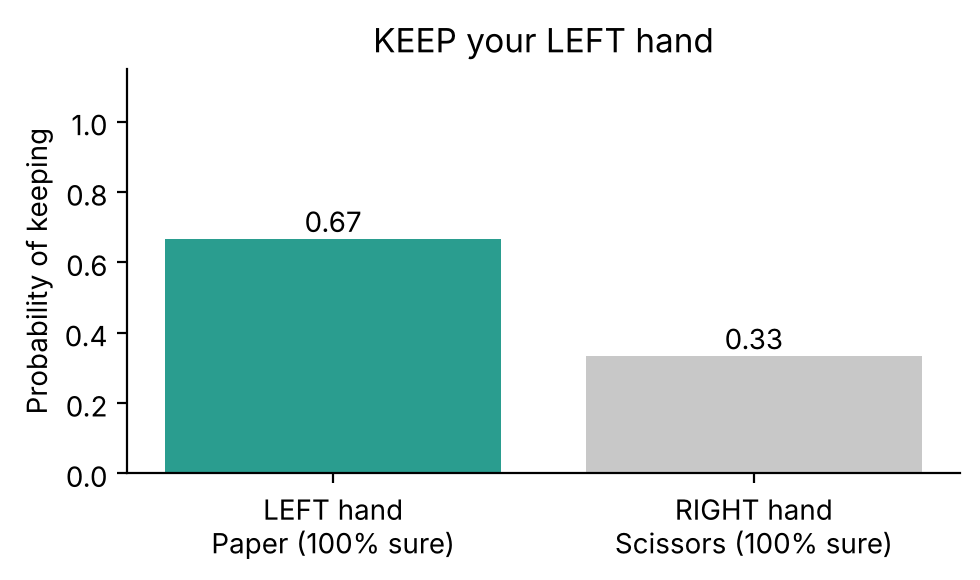

In [9]:
CONFIDENCE_WARNING = 0.70     # warn if the vision's top probability is below this


def best_guess(hand):
    """Most likely shape of a hand and how confident we are."""
    probs = to_probs(hand)
    k = int(np.argmax(probs))
    return SHAPES[k], float(probs[k])


def show_recommendation(my_hands, keep_probs, keep_index, hand_labels=("LEFT", "RIGHT")):
    """Bar chart of the keep-probabilities with the selected hand highlighted."""
    labels = []
    for i in range(2):
        shape, conf = best_guess(my_hands[i])
        labels.append(f"{hand_labels[i]} hand\n{NAMES[shape]} ({conf:.0%} sure)")
    colors = ["#2a9d8f" if i == keep_index else "#c8c8c8" for i in range(2)]
    fig, ax = plt.subplots(figsize=(5, 3))
    bars = ax.bar(labels, keep_probs, color=colors)
    for bar, prob in zip(bars, keep_probs):
        ax.text(bar.get_x() + bar.get_width() / 2, prob + 0.02, f"{prob:.2f}", ha="center")
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Probability of keeping")
    ax.set_title(f"KEEP your {hand_labels[keep_index]} hand")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()


def play_round(image_path=None, my_hands=None, opp_hands=None, rng=None,
               model=None, epsilon=0.0, hand_labels=("LEFT", "RIGHT")):
    """Run Stage 2 of one round from a photo or from typed-in hands.
    my_hands are ordered (player's own LEFT, RIGHT); each is a letter or [pR, pP, pS].
    Pass an OpponentModel and epsilon > 0 to use the adaptive mode."""
    rng = rng if rng is not None else np.random.default_rng()

    if image_path is not None:
        image_path = Path(image_path)
        if image_path.exists():
            plt.figure(figsize=(5, 4))
            plt.imshow(plt.imread(image_path))
            plt.axis("off")
            plt.title(image_path.name)
            plt.show()
        try:
            detected = detect_hands(image_path)
            my_hands, opp_hands = detected["my_hands"], detected["opp_hands"]
        except (RuntimeError, FileNotFoundError, ImportError) as err:
            print("Vision not available:", err)
            if my_hands is None:
                return None
            print("Using the hands entered manually instead.\n")

    # Report what the vision thinks, with warnings for unsure hands
    for who, hands in (("You", my_hands), ("Opponent", opp_hands)):
        for i, hand in enumerate(hands):
            shape, conf = best_guess(hand)
            name = hand_labels[i] if who == "You" else f"hand {i + 1}"
            flag = "   <-- LOW CONFIDENCE: check this hand!" if conf < CONFIDENCE_WARNING else ""
            print(f"{who:<9} {name:<7}: {NAMES[shape]:<9} ({conf:.0%} sure){flag}")

    # Strategy
    A = payoff_matrix(my_hands, opp_hands)
    keep_probs, value = solve_game(A)
    mode = "equilibrium"
    if model is not None and epsilon > 0:
        opp_letters = [best_guess(h)[0] for h in opp_hands]
        keep_probs = safe_exploit(A, model.predict(opp_letters), epsilon)
        mode = f"adaptive (epsilon = {epsilon})"
    keep = int(rng.choice(2, p=keep_probs))

    print(f"\nStrategy: {mode}")
    for i in range(2):
        print(f"  Keep {hand_labels[i]:<5}: probability {keep_probs[i]:.3f}")
    print(f"  Guaranteed expected payoff: {guaranteed_payoff(A, keep_probs[0]):+.3f}")
    print(f"\n>>> KEEP your {hand_labels[keep]} hand, WITHDRAW your {hand_labels[1 - keep]} hand.")
    show_recommendation(my_hands, keep_probs, keep, hand_labels)
    return {"matrix": A, "keep_probs": keep_probs, "keep_index": keep}


# Example 1: the scenario from the instructions, with certain labels
rng = np.random.default_rng(SEED)
print("Stage-1 advice for this round: show", recommend_stage1(rng), "\n")
_ = play_round(my_hands=["P", "S"], opp_hands=["P", "R"], rng=rng)

You       LEFT   : Paper     (100% sure)
You       RIGHT  : Scissors  (100% sure)
Opponent  hand 1 : Paper     (100% sure)
Opponent  hand 2 : Rock      (55% sure)   <-- LOW CONFIDENCE: check this hand!

Strategy: equilibrium
  Keep LEFT : probability 0.909
  Keep RIGHT: probability 0.091
  Guaranteed expected payoff: +0.091

>>> KEEP your LEFT hand, WITHDRAW your RIGHT hand.


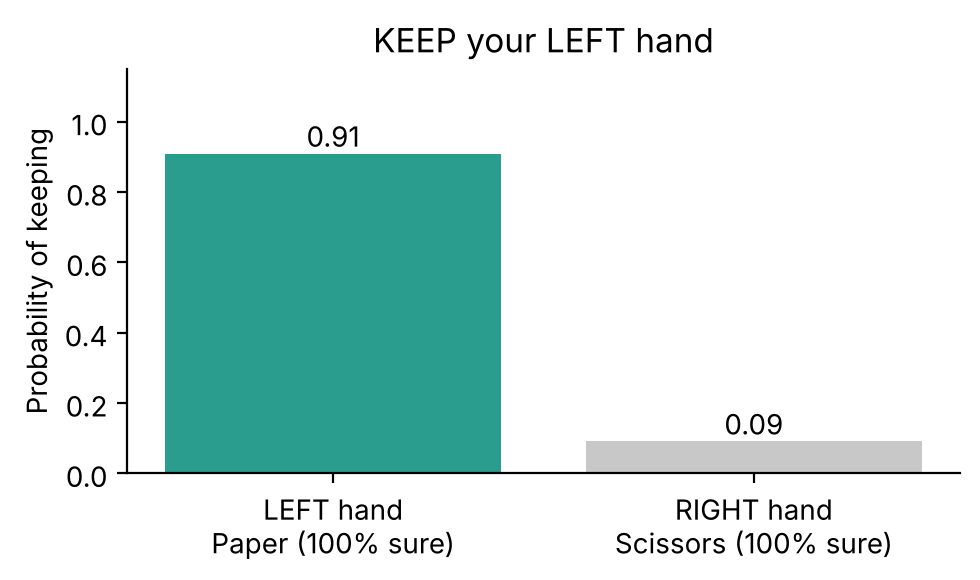

In [10]:
# Example 2: same hands, but the camera is unsure about the opponent's second hand:
# Rock 55%, Paper 5%, Scissors 40%. The strategy adjusts and the display warns.
_ = play_round(my_hands=["P", "S"], opp_hands=["P", [0.55, 0.05, 0.40]],
               rng=np.random.default_rng(SEED))

> _TODO: one or two sentences on Example 2. If that hand is really Scissors, keeping our Scissors no longer wins against it, and keeping Paper against it would lose, so the "certain" matrix is wrong. The strategy shifts strongly toward Paper (about 0.91), and the guaranteed payoff drops from +0.333 to about +0.09. Uncertainty has a real cost, and the low-confidence warning tells the player to look before trusting it._

# 3. Results

## 3.1 User guide

1. Install requirements (Section 0), open the notebook, run all cells.
2. **Before a round:** run `recommend_stage1(np.random.default_rng())` to get which pair to show.
3. **After both players show:** `play_round("images/demo/demo1.jpg")` (from a photo; or set `TEST_IMAGE` in Section 3.8), or `play_round(my_hands=["P","S"], opp_hands=["P","R"])` (typed in; our hands are listed LEFT then RIGHT).
4. Follow the **KEEP** instruction. Check any hand flagged LOW CONFIDENCE.
5. Optional adaptive mode for a long match: create `model = OpponentModel()` once, pass `model=model, epsilon=0.1` to `play_round`, and after each round call `model.update(opp_hands, index_they_kept)`.
6. The recommendation is random, so it can differ between runs; the probabilities do not.

## 3.2 Strategy tests (perception excluded)

All strategy tests use **known** hand shapes, so errors here can't come from the vision part.

**Known-answer tests.** Solved by hand first, then checked against the code.

In [11]:
# (our hands, their hands, expected keep-probabilities, expected value, reason)
known_cases = [
    ("PS", "PR", [2/3, 1/3], 1/3, "worked example in the instructions"),
    ("RP", "RP", [0, 1],     0,   "mirror pair: Paper dominates Rock"),
    ("PS", "RR", [1, 0],     1,   "opponent has no choice: Paper always wins"),
    ("RR", "PS", [0.5, 0.5], -1,  "we have no choice; they keep Paper"),
    ("RR", "RR", [0.5, 0.5], 0,   "nobody has a choice: tie"),
]

print(f"{'Us':<4}{'Opp':<5}{'Expected':<14}{'Computed':<14}{'Value':<8}Result  Reason")
for mine, opp, exp_p, exp_v, why in known_cases:
    probs, value = solve_game(payoff_matrix(list(mine), list(opp)))
    ok = np.allclose(probs, exp_p) and np.isclose(value, exp_v)
    print(f"{mine:<4}{opp:<5}{str(np.round(exp_p, 3)):<14}{str(probs.round(3)):<14}"
          f"{value:<+8.3f}{'PASS' if ok else 'FAIL':<8}{why}")
    assert ok, f"Strategy test failed for {mine} vs {opp}"
print("\nAll known-answer tests passed.")

Us  Opp  Expected      Computed      Value   Result  Reason
PS  PR   [0.667 0.333] [0.667 0.333] +0.333  PASS    worked example in the instructions
RP  RP   [0 1]         [0. 1.]       +0.000  PASS    mirror pair: Paper dominates Rock
PS  RR   [1 0]         [1. 0.]       +1.000  PASS    opponent has no choice: Paper always wins
RR  PS   [0.5 0.5]     [0.5 0.5]     -1.000  PASS    we have no choice; they keep Paper
RR  RR   [0.5 0.5]     [0.5 0.5]     +0.000  PASS    nobody has a choice: tie

All known-answer tests passed.


**Cross-check of the two solvers.** All $9 \times 9 = 81$ ordered Stage-2 situations (including identical hands) are solved by both methods. They must give the same game value, and each method's strategy must actually guarantee that value. (When several strategies are equally good, e.g. identical hands, the two methods may pick different ones, which is fine.)

In [12]:
ordered_pairs = [a + b for a in SHAPES for b in SHAPES]   # RR, RP, RS, PR, ...
max_value_gap, max_guarantee_gap = 0.0, 0.0
for ours in ordered_pairs:
    for theirs in ordered_pairs:
        A = payoff_matrix(list(ours), list(theirs))
        p_tent, v_tent = solve_2x2(A)
        p_lp, v_lp = solve_lp(A)
        max_value_gap = max(max_value_gap, abs(v_tent - v_lp))
        for p in (p_tent, p_lp):
            max_guarantee_gap = max(max_guarantee_gap, abs(guaranteed_payoff(A, p[0]) - v_lp))

n_cases = len(ordered_pairs) ** 2
print(f"Situations checked: {n_cases}")
print(f"Largest difference in game value between solvers:  {max_value_gap:.2e}")
print(f"Largest gap between a strategy's guarantee and v:  {max_guarantee_gap:.2e}")
assert max_value_gap < 1e-6 and max_guarantee_gap < 1e-6
print("Both solvers agree on every situation.")

Situations checked: 81
Largest difference in game value between solvers:  1.11e-16
Largest gap between a strategy's guarantee and v:  1.11e-16
Both solvers agree on every situation.


## 3.3 The whole game (Stage 1)

The heat map shows the Stage-2 value for every pair we could show (rows) against every pair they could show (columns): the Stage-1 game from Section 2.3.

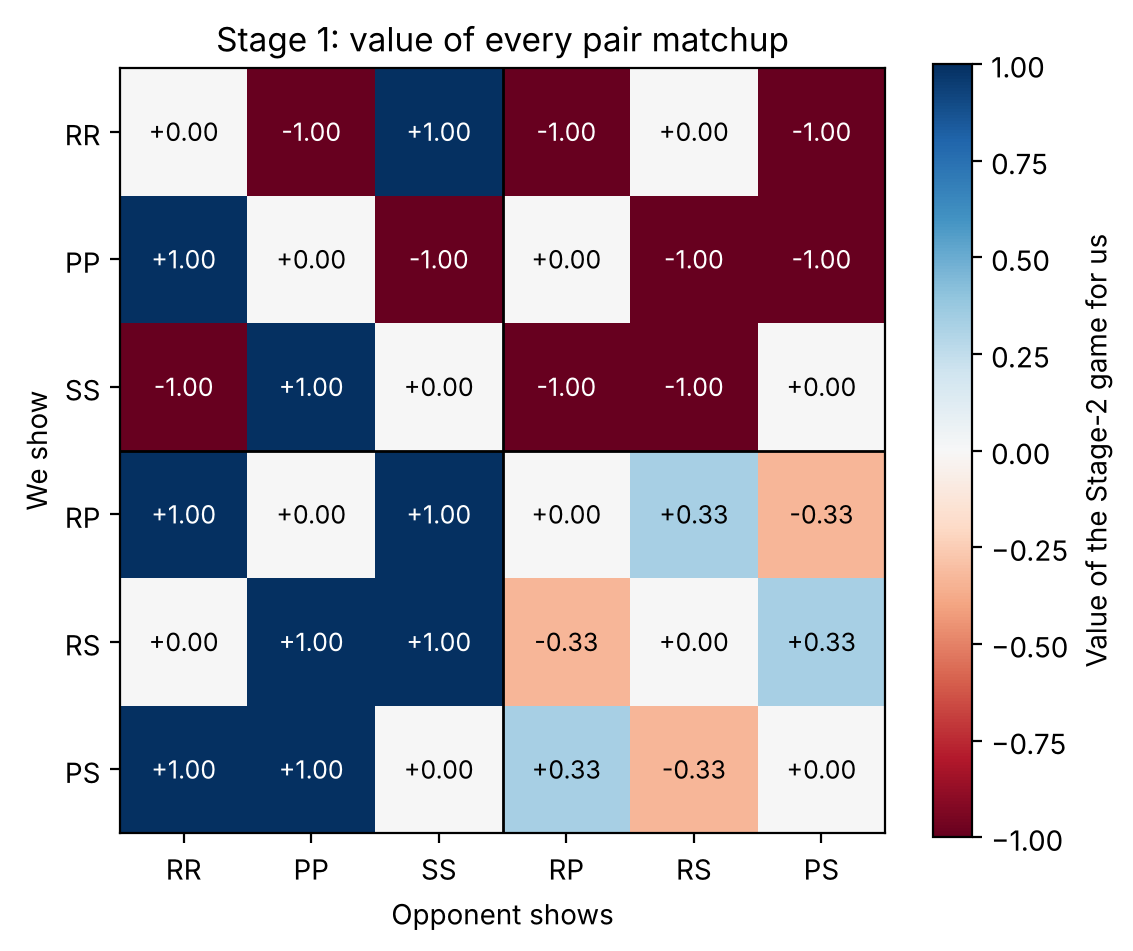

Expected payoff of each pair against an equilibrium opponent:
  RR: -0.667
  PP: -0.667
  SS: -0.667
  RP: +0.000
  RS: +0.000
  PS: +0.000

Mixed pairs only (RP, RS, PS):
[[ 0.     0.333 -0.333]
 [-0.333  0.     0.333]
 [ 0.333 -0.333  0.   ]]


In [13]:
fig, ax = plt.subplots(figsize=(5.8, 4.8))
im = ax.imshow(STAGE1_V, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(6), STAGE1_PAIRS)
ax.set_yticks(range(6), STAGE1_PAIRS)
ax.set_xlabel("Opponent shows")
ax.set_ylabel("We show")
for i in range(6):
    for j in range(6):
        v = np.round(STAGE1_V[i, j], 6) + 0.0            # avoids printing "-0.00"
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 else "black")
ax.axhline(2.5, color="k", lw=1)
ax.axvline(2.5, color="k", lw=1)
fig.colorbar(im, label="Value of the Stage-2 game for us")
ax.set_title("Stage 1: value of every pair matchup")
plt.tight_layout()
plt.show()

# Cost of identical pairs against an opponent playing the Stage-1 equilibrium
opp_eq = STAGE1_PROBS
print("Expected payoff of each pair against an equilibrium opponent:")
for pair, row in zip(STAGE1_PAIRS, STAGE1_V):
    print(f"  {pair}: {np.round(row @ opp_eq, 6) + 0.0:+.3f}")

# The 'RPS in disguise' check: mixed pairs form a cycle
print("\nMixed pairs only (RP, RS, PS):")
print(np.round(STAGE1_V[3:, 3:], 3) + 0.0)

> _TODO (strategy writer): interpret. The identical-pair rows (top-left block) are mostly losses. Each identical pair averages −2/3 against an equilibrium opponent while the mixed pairs average 0, so they're never worth showing. The bottom-right $3\times3$ block has the same pattern as plain RPS scaled by 1/3: each pair acts like its stronger shape (RP→Paper, RS→Rock, PS→Scissors). Hence the uniform Stage-1 strategy and an overall value of 0 (the game is fair)._

## 3.4 Mixed-strategy check and payoff simulation (Stage 2)

10,000 rounds of the instructions' example (seed in Section 0) against four opponent strategies. We check that (1) our random picks follow the 2/3 – 1/3 probabilities, using a **binomial test** (a p-value above 0.05 means the observed frequency is consistent with 2/3), and (2) the average payoff matches the theoretical value +1/3 **whatever the opponent does**. Error bars: 95% confidence intervals ($\pm1.96$ standard errors).

Opponent                   Our P(keep Paper)  p-value vs 2/3  Mean payoff                95% CI
Equilibrium (2/3 Paper)                0.661            0.22       +0.328   [+0.315, +0.341]
Uniform 50/50                          0.672            0.26       +0.336   [+0.321, +0.351]
Always Paper                           0.668            0.70       +0.332   [+0.322, +0.341]
Always Rock                            0.665            0.73       +0.330   [+0.311, +0.349]


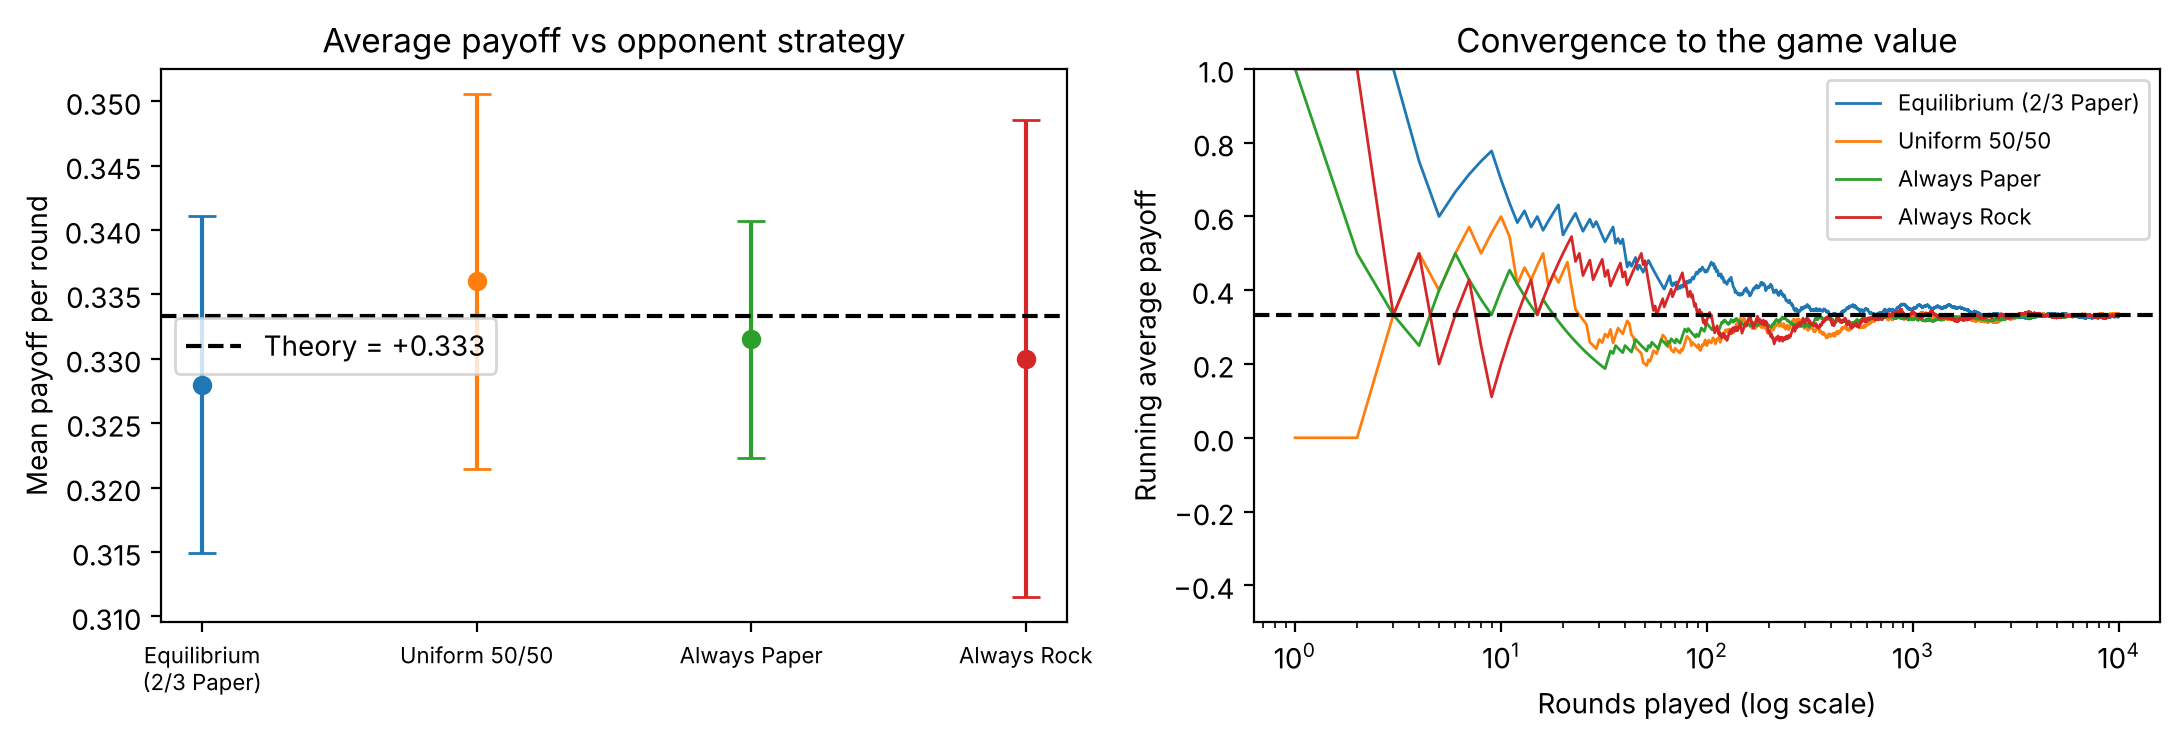

In [14]:
A_ex = payoff_matrix(["P", "S"], ["P", "R"])
p_ex, v_ex = solve_game(A_ex)
opponents = {"Equilibrium (2/3 Paper)": [2/3, 1/3], "Uniform 50/50": [0.5, 0.5],
             "Always Paper": [1.0, 0.0], "Always Rock": [0.0, 1.0]}
N = 10_000

from scipy.stats import binomtest

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
print(f"{'Opponent':<26}{'Our P(keep Paper)':>18}{'p-value vs 2/3':>16}{'Mean payoff':>13}{'95% CI':>22}")
for k, (name, q) in enumerate(opponents.items()):
    rng = np.random.default_rng(SEED + k)
    ours = rng.choice(2, size=N, p=p_ex)
    theirs = rng.choice(2, size=N, p=q)
    pay = A_ex[ours, theirs]
    mean, se = pay.mean(), pay.std(ddof=1) / np.sqrt(N)
    # Binomial test: are our picks consistent with the target probability 2/3?
    p_value = binomtest(int(np.sum(ours == 0)), N, p_ex[0]).pvalue
    print(f"{name:<26}{np.mean(ours == 0):>18.3f}{p_value:>16.2f}{mean:>+13.3f}"
          f"   [{mean - 1.96 * se:+.3f}, {mean + 1.96 * se:+.3f}]")
    ax1.errorbar(k, mean, yerr=1.96 * se, fmt="o", capsize=5)
    ax2.plot(np.arange(1, N + 1), np.cumsum(pay) / np.arange(1, N + 1), lw=1, label=name)

ax1.axhline(v_ex, ls="--", color="k", label=f"Theory = {v_ex:+.3f}")
ax1.set_xticks(range(len(opponents)), [n.replace(" (", "\n(") for n in opponents], fontsize=8)
ax1.set_ylabel("Mean payoff per round")
ax1.set_title("Average payoff vs opponent strategy")
ax1.legend()
ax2.axhline(v_ex, ls="--", color="k")
ax2.set_xscale("log")
ax2.set_ylim(-0.5, 1)
ax2.set_xlabel("Rounds played (log scale)")
ax2.set_ylabel("Running average payoff")
ax2.set_title("Convergence to the game value")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

> _TODO: interpret. The keep-frequency is within sampling error of 2/3; the payoff is the same against every opponent because the optimal mix makes the opponent's choice irrelevant (the "unexploitable" property); the gap from +1/3 is sampling error, which shrinks as $1/\sqrt{N}$._

## 3.5 How much is vision accuracy worth? (impact of perception error)

Before our camera system exists, we can still ask: **if the vision is X% accurate, how many points per round does that cost us?** This links the experimental error of the vision part directly to the system's final performance, as the data-analysis rubric asks.

**Simulation design** (10,000 rounds per accuracy level):
- Both players show a random mixed pair (the Stage-1 equilibrium).
- Each of the four hands gets its own accuracy $a$, drawn uniformly between a lower limit and 100%, because some hands are easy and some hard. The simulated vision reports the correct shape with probability $a$, otherwise a wrong one, and gives confidence $a$ (i.e. it is **calibrated**).
- The opponent sees the hands correctly and plays the Stage-2 equilibrium.
- We compare three players on **identical rounds** (paired comparison): **perfect vision**; **hard labels** (best guess treated as certain); **ours**, using probabilities (Section 2.4).

Mean accuracy   Perfect  Hard labels  Ours (soft)  Gain from soft        95% CI of gain
         100%    -0.001       -0.001       -0.001         +0.0000   [+0.0000, +0.0000]
          95%    +0.002       -0.022       -0.021         +0.0010   [+0.0001, +0.0018]
          90%    -0.003       -0.048       -0.046         +0.0021   [+0.0009, +0.0033]
          85%    +0.001       -0.065       -0.062         +0.0026   [+0.0011, +0.0042]
          80%    +0.001       -0.085       -0.081         +0.0036   [+0.0018, +0.0055]
          75%    +0.001       -0.098       -0.095         +0.0022   [+0.0001, +0.0042]
          70%    +0.001       -0.115       -0.112         +0.0031   [+0.0007, +0.0054]


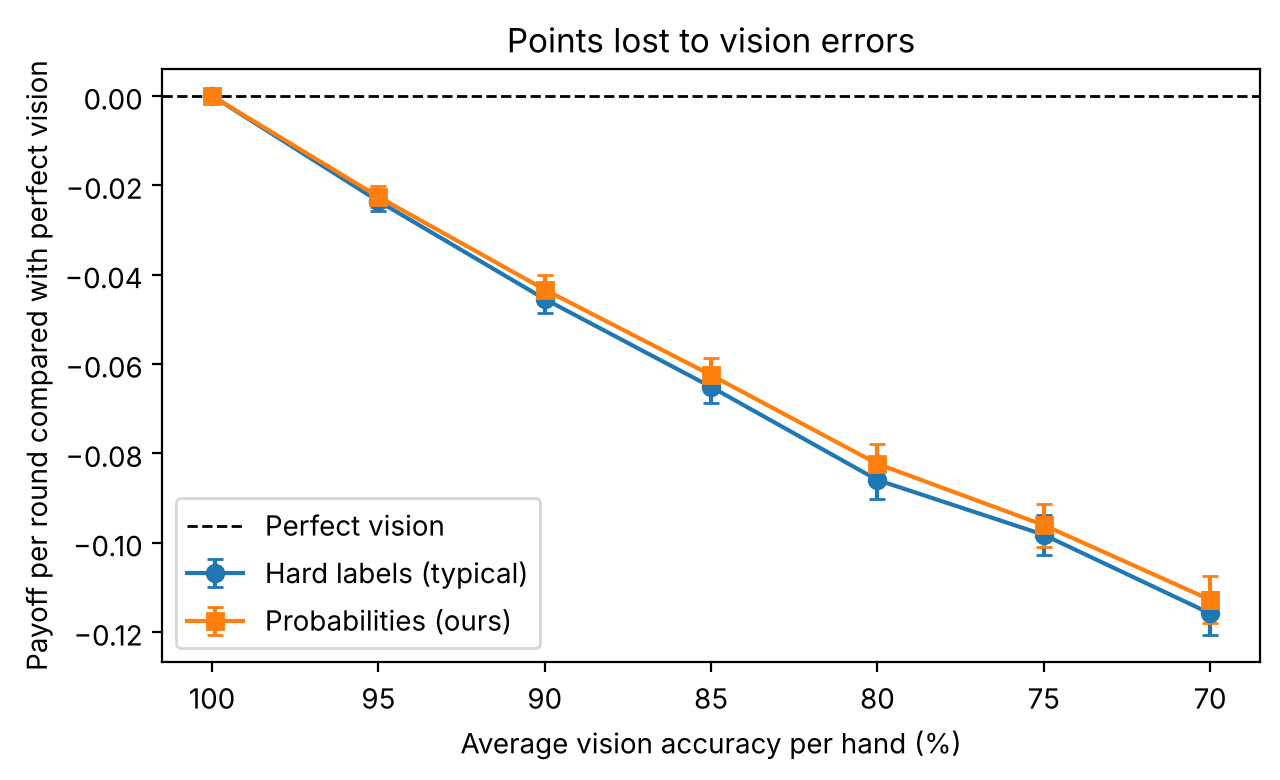

In [15]:
def simulate_vision(true_shape, accuracy, rng):
    """Simulated calibrated classifier: right with probability `accuracy`,
    and reports `accuracy` as its confidence in whatever it predicts."""
    if rng.random() < accuracy:
        predicted = true_shape
    else:
        predicted = rng.choice([s for s in SHAPES if s != true_shape])
    probs = np.full(3, (1 - accuracy) / 2)
    probs[SHAPES.index(predicted)] = accuracy
    return probs


def payoff_when_playing(A_believed, A_true, opp_probs):
    """Expected TRUE payoff if we plan with A_believed but the real game is A_true."""
    keep_probs, _ = solve_2x2(A_believed)
    return keep_probs @ A_true @ opp_probs


MIXED_PAIRS = ["RP", "RS", "PS"]
lower_limits = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4]
N_VISION = 10_000
rng = np.random.default_rng(SEED)
rows = []
for low in lower_limits:
    perfect, hard, soft = [], [], []
    for _ in range(N_VISION):
        ours = MIXED_PAIRS[rng.integers(3)]
        theirs = MIXED_PAIRS[rng.integers(3)]
        A_true = payoff_matrix(list(ours), list(theirs))
        opp_probs, _ = solve_2x2(-A_true.T)            # opponent plays equilibrium
        acc = rng.uniform(low, 1.0, size=4)
        seen_ours = [simulate_vision(s, a, rng) for s, a in zip(ours, acc[:2])]
        seen_theirs = [simulate_vision(s, a, rng) for s, a in zip(theirs, acc[2:])]
        hard_ours = [SHAPES[np.argmax(h)] for h in seen_ours]
        hard_theirs = [SHAPES[np.argmax(h)] for h in seen_theirs]

        perfect.append(payoff_when_playing(A_true, A_true, opp_probs))
        hard.append(payoff_when_playing(payoff_matrix(hard_ours, hard_theirs), A_true, opp_probs))
        soft.append(payoff_when_playing(payoff_matrix(seen_ours, seen_theirs), A_true, opp_probs))
    perfect, hard, soft = map(np.array, (perfect, hard, soft))
    gain = soft - hard
    loss_hard, loss_soft = hard - perfect, soft - perfect     # paired: same rounds
    se = lambda x: x.std(ddof=1) / np.sqrt(N_VISION)
    rows.append({"mean_acc": (low + 1) / 2, "perfect": perfect.mean(), "hard": hard.mean(),
                 "soft": soft.mean(), "gain": gain.mean(), "gain_se": se(gain),
                 "loss_hard": loss_hard.mean(), "loss_hard_se": se(loss_hard),
                 "loss_soft": loss_soft.mean(), "loss_soft_se": se(loss_soft)})

print(f"{'Mean accuracy':>13}{'Perfect':>10}{'Hard labels':>13}{'Ours (soft)':>13}"
      f"{'Gain from soft':>16}{'95% CI of gain':>22}")
for r in rows:
    print(f"{r['mean_acc']:>13.0%}{r['perfect']:>+10.3f}{r['hard']:>+13.3f}{r['soft']:>+13.3f}"
          f"{r['gain']:>+16.4f}   [{r['gain'] - 1.96 * r['gain_se']:+.4f}, "
          f"{r['gain'] + 1.96 * r['gain_se']:+.4f}]")

x = [r["mean_acc"] * 100 for r in rows]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.axhline(0, color="k", ls="--", lw=1, label="Perfect vision")
ax.errorbar(x, [r["loss_hard"] for r in rows], yerr=[1.96 * r["loss_hard_se"] for r in rows],
            fmt="o-", capsize=3, label="Hard labels (typical)")
ax.errorbar(x, [r["loss_soft"] for r in rows], yerr=[1.96 * r["loss_soft_se"] for r in rows],
            fmt="s-", capsize=3, label="Probabilities (ours)")
ax.invert_xaxis()
ax.set_xlabel("Average vision accuracy per hand (%)")
ax.set_ylabel("Payoff per round compared with perfect vision")
ax.set_title("Points lost to vision errors")
ax.legend()
plt.tight_layout()
plt.show()

> _TODO (data analysis): interpret._
> - _Perfect vision breaks even (value 0, since the opponent plays optimally too). Every drop in accuracy turns directly into lost points: read off the curve how much e.g. 90% vs 75% accuracy costs._
> - _Using probabilities recovers only a small part of the loss: a few percent. The confidence intervals of the gain sit above 0, so the effect is real, but it is small. Be honest about it: the main lesson is that **better vision matters far more** than clever use of uncertainty. The confidence warning on the display, which brings the human in, is the more practical benefit._
> - _Limitation: this assumes calibrated confidences and independent errors per hand. Once the vision part exists, re-run using our real measured accuracy and confusion matrix (Section 3.7)._

## 3.6 Adaptive mode: how much can we gain, and what can it cost?

300-round matches (Stage-1 equilibrium pairs, random left/right order), repeated 10 times each, against four opponent "personalities", for different values of the safety dial $\varepsilon$:
- **Equilibrium:** plays perfectly; nothing to exploit.
- **Rock lover:** always keeps Rock when they have it, otherwise random. A simple human-like habit our model **can** describe.
- **Random:** keeps either hand 50/50.
- **Never-lose player:** keeps a hand that can't lose if there is one. A habit that depends on the situation, **not** on a favourite shape, so our model **misreads** it. This is the stress test.

Opponent               eps=0.0  eps=0.05   eps=0.1  eps=0.25   eps=0.5   eps=1.0
Equilibrium             -0.004    +0.001    +0.009    +0.012    +0.004    +0.005
Rock lover              +0.173    +0.204    +0.233    +0.337    +0.453    +0.548
Random                  +0.179    +0.200    +0.222    +0.254    +0.299    +0.323
Never-lose player       -0.004    -0.022    -0.024    -0.054    -0.126    -0.179


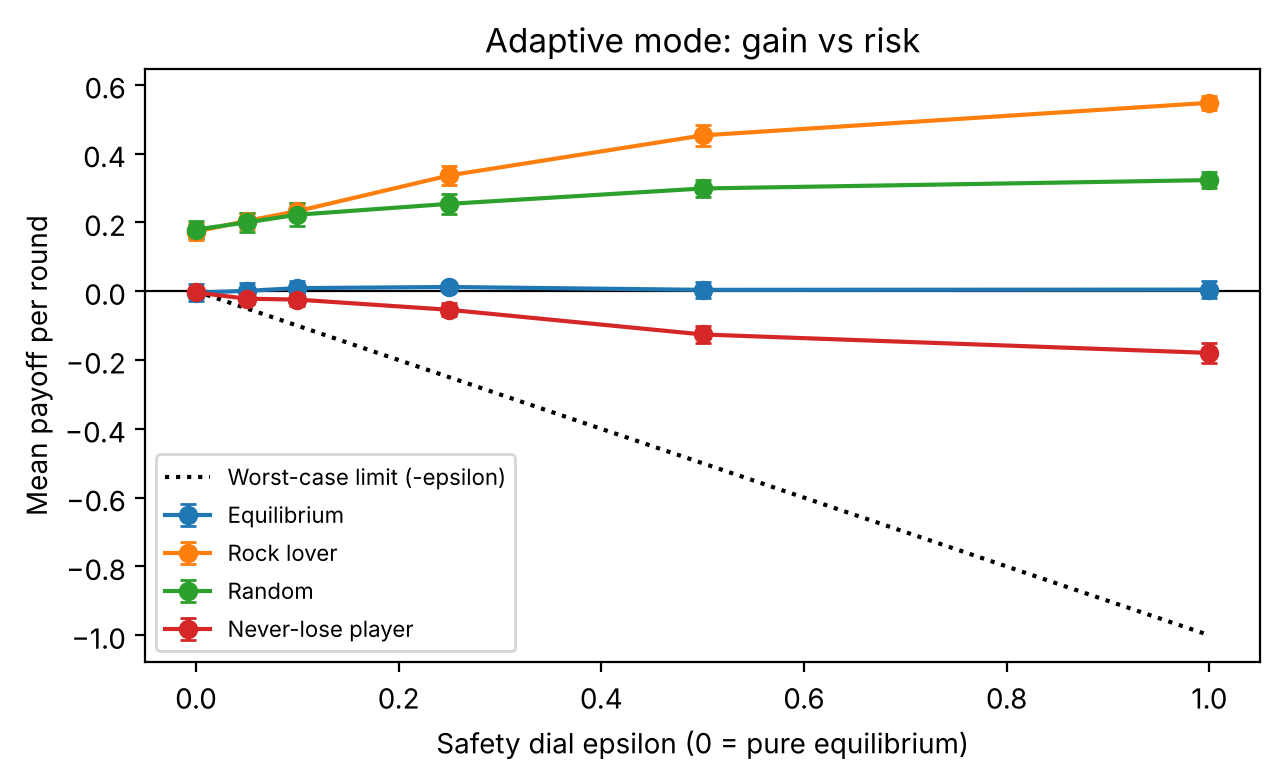

In [16]:
def opponent_choice(personality, opp_hands, A_opp, rng):
    """Index of the hand the simulated opponent keeps. A_opp is THEIR payoff matrix."""
    if personality == "Equilibrium":
        q, _ = solve_2x2(A_opp)
        return int(rng.random() >= q[0])
    if personality == "Rock lover" and "R" in opp_hands:
        return opp_hands.index("R")
    if personality == "Never-lose player":
        for k in range(2):
            if A_opp[k].min() >= 0:             # this hand never loses
                return k
    return int(rng.integers(2))                 # Random, or no special case applies


def play_match(personality, epsilon, rng, n_rounds=300):
    model = OpponentModel()
    total = 0.0
    for _ in range(n_rounds):
        ours = list(MIXED_PAIRS[rng.integers(3)])
        theirs = list(MIXED_PAIRS[rng.integers(3)])
        rng.shuffle(ours)
        rng.shuffle(theirs)
        A = payoff_matrix(ours, theirs)
        keep_probs = safe_exploit(A, model.predict(theirs), epsilon)
        mine = int(rng.choice(2, p=keep_probs))
        k = opponent_choice(personality, theirs, -A.T, rng)
        total += A[mine, k]
        model.update(theirs, k)
    return total / n_rounds


personalities = ["Equilibrium", "Rock lover", "Random", "Never-lose player"]
epsilons = [0.0, 0.05, 0.1, 0.25, 0.5, 1.0]
N_MATCHES = 10
results = {}
for name in personalities:
    means, ses = [], []
    for eps in epsilons:
        scores = [play_match(name, eps, np.random.default_rng(SEED + m)) for m in range(N_MATCHES)]
        means.append(np.mean(scores))
        ses.append(np.std(scores, ddof=1) / np.sqrt(N_MATCHES))
    results[name] = (np.array(means), np.array(ses))

print(f"{'Opponent':<20}" + "".join(f"{'eps=' + str(e):>10}" for e in epsilons))
for name in personalities:
    print(f"{name:<20}" + "".join(f"{m:>+10.3f}" for m in results[name][0]))

fig, ax = plt.subplots(figsize=(6.5, 4))
for name in personalities:
    m, se = results[name]
    ax.errorbar(epsilons, m, yerr=1.96 * se, fmt="o-", capsize=3, label=name)
ax.axhline(0, color="k", lw=0.8)
ax.plot(epsilons, [-e for e in epsilons], "k:", label="Worst-case limit (-epsilon)")
ax.set_xlabel("Safety dial epsilon (0 = pure equilibrium)")
ax.set_ylabel("Mean payoff per round")
ax.set_title("Adaptive mode: gain vs risk")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

> _TODO: interpret._
> - _Against the Rock lover and the Random player, payoff rises steadily with $\varepsilon$: the model learns their habit and punishes it._
> - _Against the Equilibrium player, there is no gain and no loss, as expected: nothing to exploit._
> - _Against the Never-lose player, our model is **wrong** about why they choose, so exploiting **costs** us. But the loss always stays above the $-\varepsilon$ limit, so the safety guarantee works. This is the key trade-off: exploiting is only as good as the opponent model._
> - _Choice of default: we keep $\varepsilon = 0$ for a single competitive round and suggest about 0.1 for long matches. Explain why using the numbers._

## 3.7 Vision results

> _TODO (vision): state the test-set size, how photos were chosen and the conditions covered (from `images/photos.csv`). Only `images/test/` is used here._

**How each measure is defined:**

| Measure | Counted per | Correct when |
|---|---|---|
| Hand detection | photo | exactly 4 hands found |
| Player assignment (ML) | hand | the classifier + "two each" rule puts the hand with the right player |
| Player assignment (rule baseline) | hand | "fingertips above wrist = ours" is right |
| Shape classification | hand | the most likely shape is the true shape |
| Whole photo | photo | 4 hands found and every owner and shape right, so the strategy gets correct inputs |

Every accuracy comes with a **95% Wilson confidence interval**, which stays sensible for small test sets and accuracies near 100%, unlike the usual ±1.96 standard errors. The **calibration** table checks the assumption behind Sections 2.4 and 3.5: when the classifier says "90% sure", is it right about 90% of the time?

In [17]:
def wilson_interval(correct, total, z=1.96):
    # 95% confidence interval for an accuracy (Wilson score interval).
    if total == 0:
        return (float("nan"), float("nan"))
    p = correct / total
    centre = (p + z**2 / (2 * total)) / (1 + z**2 / total)
    half = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return centre - half, centre + half


def print_accuracy(name, correct, total):
    low, high = wilson_interval(correct, total)
    print(f"{name:<36}{correct:>5}/{total:<5}{correct / max(total, 1):>8.1%}   95% CI [{low:.1%}, {high:.1%}]")


def evaluate_vision(split="test"):
    # Full vision evaluation on one split. Returns the numbers for the report.
    rows = [r for r in csv.DictReader(open(HAND_LABELS)) if r["split"] == split]
    photos = sorted({r["filename"] for r in rows})
    det_ok = owner_ok = rule_ok = shape_ok = photo_ok = n_hands = 0
    confusion = np.zeros((3, 3), dtype=int)
    confidences, correct_flags = [], []
    for filename in photos:
        labels = [r for r in rows if r["filename"] == filename]
        found = find_hands(IMAGE_DIR / split / filename)
        det_ok += len(found) == 4
        if len(found) < 2:
            n_hands += len(labels)
            continue
        p_ours = OWNER_MODEL.predict_proba(np.array([owner_features(h) for h in found]))[:, 1]
        picked = set(np.argsort(-p_ours)[:2])
        all_right = len(found) == 4
        for r in labels:
            i = int(r["hand_index"])
            n_hands += 1
            if i >= len(found):
                all_right = False
                continue
            is_ours = r["owner"] == "us"
            owner_ok += (i in picked) == is_ours
            rule_ok += upright_rule(found[i]) == is_ours
            probs = SHAPE_MODEL.predict_proba([shape_features(found[i])])[0]
            pred = SHAPE_MODEL.classes_[np.argmax(probs)]
            shape_ok += pred == r["shape"]
            confusion[SHAPES.index(r["shape"]), SHAPES.index(pred)] += 1
            confidences.append(probs.max())
            correct_flags.append(pred == r["shape"])
            all_right &= ((i in picked) == is_ours) and pred == r["shape"]
        photo_ok += all_right

    print(f"Test set: {len(photos)} photos, {n_hands} labelled hands\n")
    print_accuracy("Hand detection (photos)", det_ok, len(photos))
    print_accuracy("Player assignment, ML (hands)", owner_ok, n_hands)
    print_accuracy("Player assignment, rule (hands)", rule_ok, n_hands)
    print_accuracy("Shape classification (hands)", shape_ok, n_hands)
    print_accuracy("Whole photo correct (photos)", photo_ok, len(photos))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    ax1.imshow(confusion, cmap="Blues")
    ax1.set_xticks(range(3), [NAMES[s] for s in SHAPES])
    ax1.set_yticks(range(3), [NAMES[s] for s in SHAPES])
    ax1.set_xlabel("Predicted")
    ax1.set_ylabel("True")
    for a in range(3):
        for b in range(3):
            ax1.text(b, a, confusion[a, b], ha="center", va="center")
    ax1.set_title("Shape confusion matrix (test)")

    confidences, correct_flags = np.array(confidences), np.array(correct_flags)
    bins = [(0.33, 0.5), (0.5, 0.7), (0.7, 0.9), (0.9, 1.01)]
    print(f"\n{'Confidence':<14}{'Hands':>6}{'Avg confidence':>16}{'Fraction correct':>18}")
    for lo, hi in bins:
        inside = (confidences >= lo) & (confidences < hi)
        if inside.sum():
            print(f"{lo:.2f}-{min(hi, 1):.2f}{inside.sum():>10}{confidences[inside].mean():>16.2f}"
                  f"{correct_flags[inside].mean():>18.2f}")
            ax2.plot(confidences[inside].mean(), correct_flags[inside].mean(), "o", ms=4 + inside.sum() ** 0.5)
    ax2.plot([0.33, 1], [0.33, 1], "k--", label="Perfectly calibrated")
    ax2.set_xlabel("Average confidence")
    ax2.set_ylabel("Fraction correct")
    ax2.set_title("Calibration (test)")
    ax2.legend()
    plt.tight_layout()
    plt.show()
    return {"shape_accuracy": shape_ok / max(n_hands, 1), "confusion": confusion}


if labelled_photos_exist("test") and OWNER_MODEL is not None:
    vision_results = evaluate_vision("test")
else:
    print("No labelled test photos yet - the evaluation runs here automatically once they exist.")
    print("Example of how an accuracy will be reported:")
    print_accuracy("Shape classification (hands)", 45, 50)

No labelled test photos yet - the evaluation runs here automatically once they exist.
Example of how an accuracy will be reported:
Shape classification (hands)           45/50      90.0%   95% CI [78.6%, 95.7%]


> _TODO (vision): interpret. Accuracy by condition (bright vs dim, etc.); 2–3 failure images with the reason; ML vs rule for player assignment; whether the confidences are calibrated; and the expected points lost per round at our measured shape accuracy, read off the Section 3.5 curve. That last one links vision error to its impact on the game, which the data-analysis rubric asks for._

## 3.8 Demonstration images

The first cell below tests **one** image at a time (change `TEST_IMAGE`); the second runs all five. The expected labels let you compare the output with the truth. The recommendation is random, so it can differ between runs.

| Image | Our LEFT | Our RIGHT | Opponent hands | Conditions |
|---|---|---|---|---|
| `demo1.jpg` | | | | |
| `demo2.jpg` | | | | |
| `demo3.jpg` | | | | |
| `demo4.jpg` | | | | |
| `demo5.jpg` | | | | |

In [18]:
# Test ONE image: change the file name and run this cell.
TEST_IMAGE = IMAGE_DIR / "demo" / "demo1.jpg"
if TEST_IMAGE.exists():
    play_round(TEST_IMAGE, rng=np.random.default_rng())
else:
    print(f"{TEST_IMAGE} not found yet.")

images/demo/demo1.jpg not found yet.


In [19]:
# Run every demonstration image through the full pipeline (once the photos exist).
demo_images = sorted((IMAGE_DIR / "demo").glob("*.jp*g")) + sorted((IMAGE_DIR / "demo").glob("*.png"))
if not demo_images:
    print("No demo images yet: add 5 photos to images/demo/.")
for path in demo_images:
    print("=" * 60, f"\n{path.name}")
    play_round(path, rng=np.random.default_rng(SEED))

No demo images yet: add 5 photos to images/demo/.


# 4. Discussion

> _TODO: write each as prose._

**Why we chose this approach**
- Game theory: maximin/Nash equilibrium gives a guarantee backed by a theorem. Solving the whole game showed something the Stage-2 analysis alone can't (never show identical hands; Stage 1 = RPS).
- Two solvers: the closed-form formula breaks under dominance; LP generalizes; cross-checking gives confidence in correctness.
- Probabilities from vision: real sensors are uncertain; a cyber-physical system should reason about that rather than ignore it.
- Vision: why transfer learning plus small classifiers on hand points, over a CNN trained on mismatched Kaggle images; how the ML owner classifier compared with the fixed upright rule on real photos.

**Limitations of our tools** (needed for "Exceeds" on Engineering Tools)
- Equilibrium assumes a rational opponent and ignores human habits. Adaptive mode addresses this, but only as well as its model fits (Never-lose result).
- The probability approach relies on calibrated confidences; the gain is modest; better vision matters more.
- The simulations assume independent errors per hand; real errors may be correlated (e.g. a dim photo affects all four hands).
- The pre-trained model's behaviour on upside-down hands, unusual skin tones or lighting is out of our control. Report what testing showed.

**Problems we hit and how we solved them**
- _Fill in from experience: camera, lighting, orientation rule, misclassified scissors, etc._

**Societal and economic impact** (stick to implications of _this_ kind of system)
- The same pattern drives real decision aids: sense → interpret → recommend → human acts (driver assistance, clinical decision support, security-patrol scheduling, which uses this same game theory).
- Our Section 3.5 result generalizes: sensor errors have a **measurable cost** in decisions, and systems should report their confidence to humans (our low-confidence warning).
- Responsibility: when a recommendation built on a misread input is wrong, who is accountable? Quantify with our own error rates.
- Fairness: does recognition accuracy vary with skin tone, hand size or lighting? Report what our test set can and can't show.
- Privacy: cameras capturing people; storage and consent.
- Uncertainty (needed for "Exceeds"): our test set is small, so real-world performance could differ. Give a confidence interval on accuracy.

**Future work**
- Live webcam play, automatic winner detection, calibrating confidences (e.g. temperature scaling), a richer opponent model that uses the situation, not just favourite shapes (which would fix the Never-lose weakness).

# 5. Conclusion

> _TODO: what we learned (technical and non-technical), the hardest parts and how we overcame them, main results in a few sentences. The instructor explicitly asks for "your journey"._

# 6. Team Contributions

| Member | Main contributions | Shared tasks |
|---|---|---|
| _Name 1_ | Game theory, solvers, whole-game analysis, uncertainty and adaptive modes, simulations (2.2–2.5, 3.2–3.6) | |
| _Name 2_ | Camera setup, photo collection and labelling, training and tuning the vision classifiers, accuracy and calibration tests (2.6, 2.7, 3.7) | |
| _Name 3_ | | |
| _Name 4_ | | |
| _Name 5_ | | |

> _TODO: confirm roles. Every member should be able to explain the whole pipeline._

# 7. Bibliography

> _TODO: add any model, dataset, tutorial, code or AI assistance actually used, as the course policy requires; remove anything not used._

1. J. von Neumann, "Zur Theorie der Gesellschaftsspiele," _Mathematische Annalen_, vol. 100, pp. 295–320, 1928.
2. J. Nash, "Non-cooperative games," _Annals of Mathematics_, vol. 54, no. 2, pp. 286–295, 1951.
3. R. Selten, "Spieltheoretische Behandlung eines Oligopolmodells mit Nachfrageträgheit," _Zeitschrift für die gesamte Staatswissenschaft_, vol. 121, pp. 301–324, 1965. (subgame perfection / backward induction)
4. S. Ganzfried and T. Sandholm, "Safe opponent exploitation," _ACM Transactions on Economics and Computation_, vol. 3, no. 2, 2015.
5. C. Guo, G. Pleiss, Y. Sun and K. Q. Weinberger, "On calibration of modern neural networks," _Proc. ICML_, 2017.
6. E. Chen, AISE 3350A Lecture notes, Week 2, Lecture 1, Western University, Sept. 15, 2026.
7. P. Virtanen _et al._, "SciPy 1.0: fundamental algorithms for scientific computing in Python," _Nature Methods_, vol. 17, pp. 261–272, 2020.
8. C. R. Harris _et al._, "Array programming with NumPy," _Nature_, vol. 585, pp. 357–362, 2020.
9. J. D. Hunter, "Matplotlib: A 2D graphics environment," _Computing in Science & Engineering_, vol. 9, no. 3, pp. 90–95, 2007.
10. F. Zhang _et al._, "MediaPipe Hands: On-device real-time hand tracking," arXiv:2006.10214, 2020. Model file: https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task
11. C. Lugaresi _et al._, "MediaPipe: A framework for building perception pipelines," arXiv:1906.08172, 2019.
12. F. Pedregosa _et al._, "Scikit-learn: Machine learning in Python," _Journal of Machine Learning Research_, vol. 12, pp. 2825–2830, 2011.
13. E. B. Wilson, "Probable inference, the law of succession, and statistical inference," _Journal of the American Statistical Association_, vol. 22, no. 158, pp. 209–212, 1927.
14. _If used:_ sanikamal (Kaggle user), "Rock Paper Scissors Dataset," Kaggle. https://www.kaggle.com/datasets/sanikamal/rock-paper-scissors-dataset